# Atividade 2 — Regressão linear múltipla: preços de casas na Califórnia

## Objetivos

- Treinar uma regressão linear com **8 variáveis de entrada** em PyTorch (`nn.Linear(8, 1)`, `nn.MSELoss`, `optim.SGD`) para prever o valor mediano das casas de um quarteirão da Califórnia.
- Dividir os dados em **treino, validação e teste (70/15/15)** e padronizar entradas e saída com `StandardScaler` ajustado **só no treino**.
- Avaliar o modelo em dólares (RMSE no teste) e compará-lo com um baseline que sempre prevê o preço médio do treino.
- Interpretar os pesos aprendidos.

O modelo é $\hat{y} = w_0 + w_1 x_1 + \dots + w_8 x_8$, o mesmo do notebook 2.6, agora com 8 entradas.

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn, optim

SEED = 1234
torch.manual_seed(SEED)
np.random.seed(SEED)

## Dados

### Download e leitura

O California Housing vem no scikit-learn (baixado na primeira execução, sem login). Cada linha é um **quarteirão** (*block group*) do censo de 1990.

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares
print('X:', X.shape, ' y:', y.shape)
X.head()

X: (20640, 8)  y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### O que significa cada variável

| Variável | Significado |
|---|---|
| `MedInc` | renda mediana das famílias do quarteirão (em dezenas de milhares de dólares) |
| `HouseAge` | idade mediana das casas (anos) |
| `AveRooms` | média de cômodos por domicílio |
| `AveBedrms` | média de quartos por domicílio |
| `Population` | população do quarteirão |
| `AveOccup` | média de moradores por domicílio |
| `Latitude` | latitude (quanto maior, mais ao norte) |
| `Longitude` | longitude (quanto mais negativa, mais ao oeste, perto do litoral) |
| **`MedHouseVal`** (alvo $y$) | valor mediano das casas, em **centenas de milhares de dólares** (ex.: 2,0 = US$ 200.000) |

In [3]:
pd.set_option('display.width', 200)
dados.frame.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


**Observações:** o alvo tem teto em 5,0 (US$ 500 mil): o censo cortou os valores maiores, o que cria um "degrau" nos dados e limita o que qualquer modelo consegue acertar nessa faixa. Além disso, `AveRooms`, `AveBedrms`, `AveOccup` e `Population` têm valores máximos muito acima da mediana (*outliers*), e as escalas das variáveis são muito diferentes, o que justifica a padronização feita adiante.

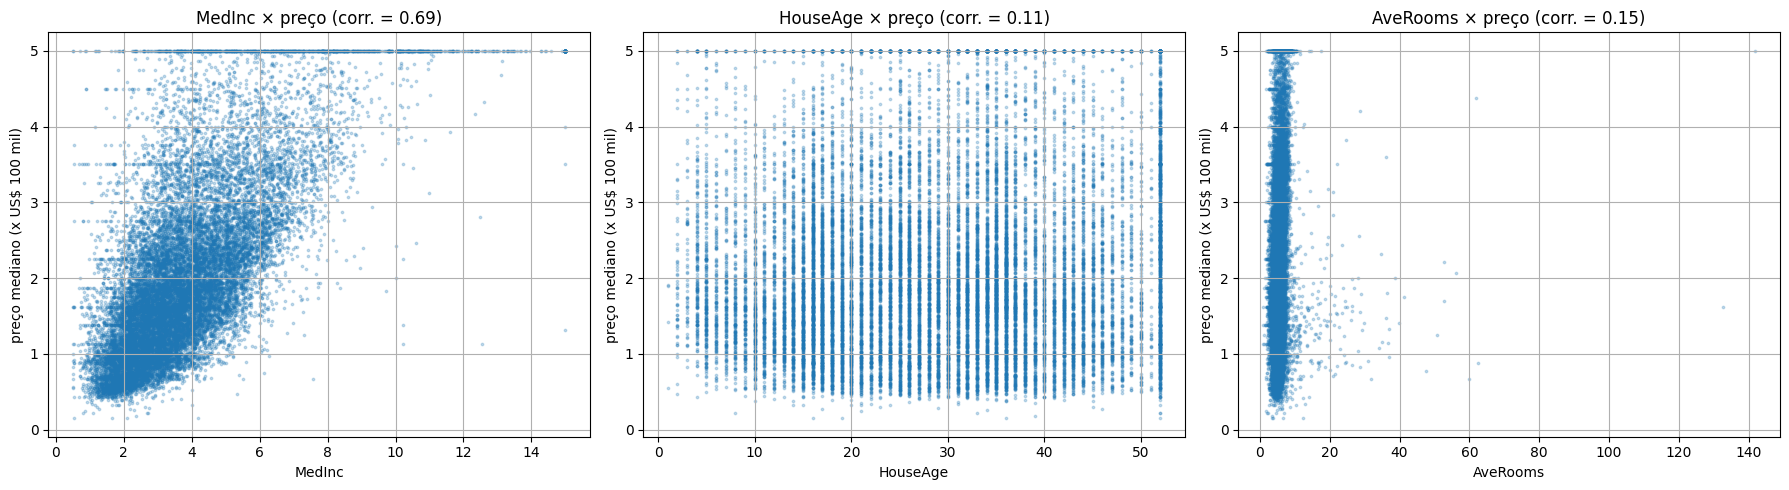

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['MedInc', 'HouseAge', 'AveRooms']):
    ax.scatter(X[col], y, s=3, alpha=0.25)
    ax.set_xlabel(col)
    ax.set_ylabel('preço mediano (x US$ 100 mil)')
    ax.set_title(f'{col} × preço (corr. = {X[col].corr(y):.2f})')
    ax.grid(True)
plt.tight_layout()
plt.show()

- `MedInc` tem relação positiva e clara com o preço: quarteirões mais ricos têm casas mais caras (e o teto em 5,0 aparece como a linha horizontal no topo).
- `HouseAge` mostra pouca relação linear com o preço.
- `AveRooms` tem correlação fraca e muitos outliers (valores extremos à direita).

## Treino, validação e teste (70/15/15)

Primeiro separamos 70% para treino; os 30% restantes são divididos ao meio em validação e teste, sempre com `random_state` fixo para a divisão ser reprodutível. O conjunto de **validação** acompanha o treino; o de **teste** só é usado no final, uma única vez.

In [5]:
x_train_raw, x_tmp_raw, y_train_raw, y_tmp_raw = train_test_split(
    X.values, y.values.reshape(-1, 1), test_size=0.30, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_tmp_raw, y_tmp_raw, test_size=0.50, random_state=42)

print('treino:    ', x_train_raw.shape, y_train_raw.shape)
print('validação: ', x_val_raw.shape, y_val_raw.shape)
print('teste:     ', x_test_raw.shape, y_test_raw.shape)

treino:     (14448, 8) (14448, 1)
validação:  (3096, 8) (3096, 1)
teste:      (3096, 8) (3096, 1)


## Padronização

$z = (x - \mu)/\sigma$, com $\mu$ e $\sigma$ calculados **só no treino** (`fit`) e aplicados à validação e ao teste (`transform`). Se usássemos todos os dados, informação de validação/teste vazaria para o treino. A saída $y$ também é padronizada; `inverse_transform` traz as previsões de volta para dólares.

In [6]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

def to_tensor(a):
    return torch.from_numpy(a).float()   # float32, sem requires_grad (são dados, não parâmetros)

x_train, x_val, x_test = [to_tensor(x_scaler.transform(a)) for a in (x_train_raw, x_val_raw, x_test_raw)]
y_train, y_val, y_test = [to_tensor(y_scaler.transform(a)) for a in (y_train_raw, y_val_raw, y_test_raw)]

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('média das colunas de x_train (≈0):', x_train.mean(0).numpy().round(3))
print('desvio das colunas de x_train (≈1):', x_train.std(0).numpy().round(3))

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
média das colunas de x_train (≈0): [-0. -0.  0.  0.  0. -0. -0.  0.]
desvio das colunas de x_train (≈1): [1. 1. 1. 1. 1. 1. 1. 1.]


## Modelo

`nn.Linear(8, 1)` tem `weight` de shape (1, 8), um peso por variável, e `bias` de shape (1,). O bias é da própria camada, então não precisamos da coluna de uns.

In [7]:
model = nn.Linear(8, 1)
print('weight:', model.weight)
print('bias:  ', model.bias)

weight: Parameter containing:
tensor([[-0.3331, -0.0694, -0.1698, -0.0943, -0.3123,  0.1419, -0.3169, -0.0225]],
       requires_grad=True)
bias:   Parameter containing:
tensor([0.1229], requires_grad=True)


## Treinamento

Mesmas funções `train_epoch` / `validate_epoch` do 2.6. Uma época é um passo de gradiente descendente com todo o conjunto de treino (*full batch*).

In [8]:
lr = 0.1
n_epochs = 300
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()

def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

In [9]:
train_losses, val_losses = [], []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    val_loss = validate_epoch(model, criterion, x_val, y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 30 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch[30/300], Train Loss: 0.4200, Val Loss: 0.4310
Epoch[60/300], Train Loss: 0.4018, Val Loss: 0.4140
Epoch[90/300], Train Loss: 0.3949, Val Loss: 0.4076
Epoch[120/300], Train Loss: 0.3923, Val Loss: 0.4052
Epoch[150/300], Train Loss: 0.3913, Val Loss: 0.4043
Epoch[180/300], Train Loss: 0.3909, Val Loss: 0.4040
Epoch[210/300], Train Loss: 0.3908, Val Loss: 0.4039
Epoch[240/300], Train Loss: 0.3907, Val Loss: 0.4038
Epoch[270/300], Train Loss: 0.3907, Val Loss: 0.4038
Epoch[300/300], Train Loss: 0.3907, Val Loss: 0.4038


## Curvas de custo de treino e de validação

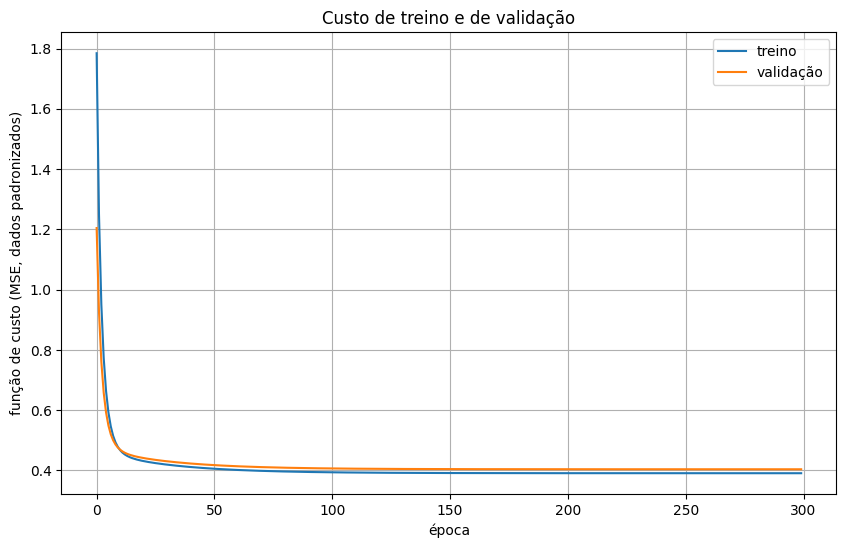

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

As duas curvas caem rápido e se estabilizam juntas, sem folga entre elas: **não há overfitting** (um modelo linear com 8 pesos e 14 mil amostras tem pouca capacidade para decorar o treino). O custo estabiliza num patamar alto, o que indica que o limite é a **capacidade do modelo** (underfitting), não o treino.

## Avaliação no teste: RMSE em dólares e baseline

In [11]:
model.eval()
with torch.no_grad():
    y_pred_test = model(x_test)

# volta para a escala original (centenas de milhares) e converte para dólares
y_pred_test_usd = y_scaler.inverse_transform(y_pred_test.numpy()) * 100_000
y_test_usd = y_test_raw * 100_000

rmse_model = np.sqrt(np.mean((y_pred_test_usd - y_test_usd) ** 2))

# baseline: sempre prevê o preço médio do TREINO
baseline_usd = y_train_raw.mean() * 100_000
rmse_baseline = np.sqrt(np.mean((baseline_usd - y_test_usd) ** 2))

print(f'preço médio do treino (baseline): US$ {baseline_usd:,.0f}')
print(f'RMSE baseline no teste: US$ {rmse_baseline:,.0f}')
print(f'RMSE do modelo no teste: US$ {rmse_model:,.0f}')
print(f'redução do erro: {(1 - rmse_model / rmse_baseline) * 100:.1f}%')

preço médio do treino (baseline): US$ 206,924
RMSE baseline no teste: US$ 114,992
RMSE do modelo no teste: US$ 72,117
redução do erro: 37.3%


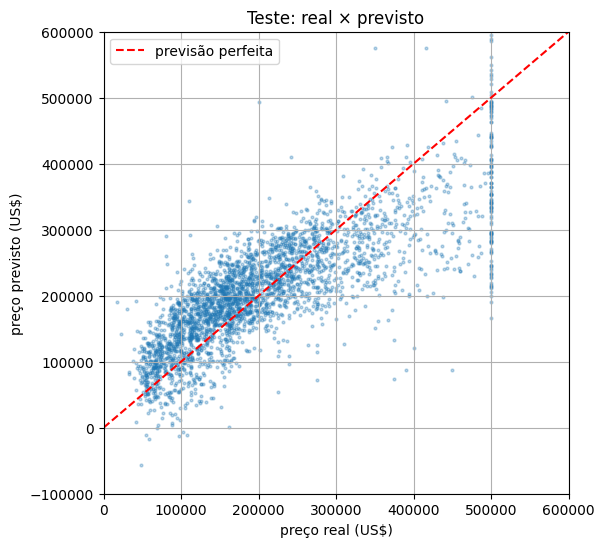

In [12]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_usd, y_pred_test_usd, s=4, alpha=0.3)
lim = [0, 600_000]
plt.plot(lim, lim, 'r--', label='previsão perfeita')
plt.xlim(lim); plt.ylim(-100_000, 600_000)
plt.xlabel('preço real (US$)')
plt.ylabel('preço previsto (US$)')
plt.title('Teste: real × previsto')
plt.legend()
plt.grid(True)
plt.show()

## Pesos aprendidos

bias (w0): 1.2961961282087486e-08

Latitude     -0.764
Longitude    -0.742
AveRooms     -0.259
AveOccup     -0.036
Population   -0.000
HouseAge      0.107
AveBedrms     0.301
MedInc        0.735
dtype: float32


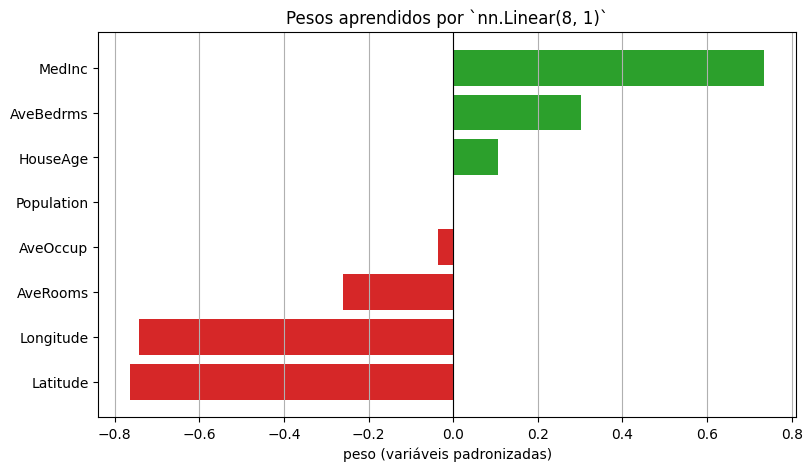

In [13]:
pesos = pd.Series(model.weight.detach().numpy().ravel(), index=X.columns).sort_values()
print('bias (w0):', model.bias.item())
print()
print(pesos.round(3))

plt.figure(figsize=(9, 5))
cores = ['tab:red' if v < 0 else 'tab:green' for v in pesos]
plt.barh(pesos.index, pesos.values, color=cores)
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('peso (variáveis padronizadas)')
plt.title('Pesos aprendidos por `nn.Linear(8, 1)`')
plt.grid(True, axis='x')
plt.show()

### Quais variáveis mais aumentam e quais mais diminuem o preço previsto?

- **Mais aumentam o preço:** `MedInc` (peso ≈ +0,74) é a variável que mais aumenta o preço: um quarteirão com renda 1 desvio-padrão acima da média tem preço previsto ≈ 0,74 desvio-padrão acima da média. Em seguida vêm `AveBedrms` (≈ +0,30) e, bem menos, `HouseAge` (≈ +0,11).
- **Mais diminuem o preço:** `Latitude` (≈ −0,76) e `Longitude` (≈ −0,74), com magnitude parecida à da renda. Como são usadas juntas, representam a localização: preço cai quanto mais ao norte e quanto mais a leste (para o interior), ou seja, o modelo associa preços mais altos ao litoral e ao sul do estado (região de Los Angeles e San Diego). É uma aproximação linear: a Bay Area, no norte, também é cara, e o modelo linear não consegue representar isso. Também reduz o preço, em menor grau, `AveRooms` (≈ −0,26).
- **Quase irrelevantes:** `Population` (≈ 0) e `AveOccup` (≈ −0,04).

Atenção: `AveRooms` com peso negativo e `AveBedrms` com peso positivo parece contraintuitivo. Isso acontece porque as duas variáveis são muito **correlacionadas** entre si: o modelo usa a diferença entre elas, então o sinal de cada uma isoladamente não deve ser lido como causal.

### Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?

Um peso $w_j$ diz quanto o preço previsto muda **por unidade** da variável $j$. Sem padronização, as unidades são diferentes: `MedInc` varia de 0,5 a 15, `Population` vai de 3 a 35.000 e `Latitude` varia em poucos graus. Uma variável medida em números grandes terá um peso pequeno só por causa da escala, e uma em números pequenos terá um peso grande, sem que isso diga algo sobre a importância. Com a padronização, todas passam a ter média 0 e desvio-padrão 1, então cada peso passa a significar "quanto o preço (em desvios-padrão) muda quando a variável sobe 1 desvio-padrão", uma unidade comum, e as magnitudes passam a ser comparáveis.

In [14]:
# Pesos de volta à escala original (para ver o efeito em dólares por unidade de cada variável)
w_orig = model.weight.detach().numpy().ravel() * y_scaler.scale_[0] / x_scaler.scale_
print('Efeito aproximado de +1 unidade da variável no preço previsto (US$):')
print(pd.Series(w_orig * 100_000, index=X.columns).round(0).sort_values())

Efeito aproximado de +1 unidade da variável no preço previsto (US$):
Longitude    -42887.0
Latitude     -41398.0
AveRooms     -12241.0
AveOccup       -338.0
Population       -0.0
HouseAge        977.0
MedInc        44651.0
AveBedrms     77825.0
dtype: float64


Na escala original, os pesos deixam de ser comparáveis: `Latitude` e `Longitude` parecem ter efeito grande por unidade porque 1 grau é uma variação enorme, e `Population` parece desprezível porque 1 pessoa é uma variação ínfima. Isso confirma por que a comparação deve ser feita com os pesos das variáveis padronizadas.

## Conclusão

**O modelo é bom o suficiente?** Ele é claramente melhor que o baseline: o RMSE no teste caiu de cerca de US$ 115 mil (prever sempre a média) para cerca de US$ 72 mil, uma redução de ~37%. Mas um erro típico de US$ 72 mil sobre um preço médio de ~US$ 207 mil (mais de 30%) é grande, e o modelo não é bom o suficiente para uso prático. As curvas de treino e validação ficam juntas e num patamar alto (underfitting), o que indica que o problema é a limitação do modelo linear, não falta de treino ou dados. O gráfico real × previsto também mostra o efeito do teto de US$ 500 mil e que o modelo erra mais nos imóveis mais caros.

**O que eu tentaria para melhorar:**
1. **Capturar a não linearidade da localização:** latitude e longitude entram de forma linear, mas o efeito é regional (litoral × interior, grandes cidades). Criar features de localização (distância até Los Angeles/San Francisco, *clusters*) ou usar uma rede neural com camadas ocultas e ativações não lineares.
2. **Engenharia de atributos:** tratar *outliers* e usar transformações (log de `Population`/`AveOccup`, termos de interação e polinomiais, como `MedInc²`).
3. **Lidar com o teto de 5,0:** remover ou tratar os exemplos truncados, que distorcem o ajuste.
4. **Modelos mais flexíveis** (árvores/gradient boosting ou uma MLP) e ajuste de hiperparâmetros (taxa de aprendizado, épocas, mini-batches) com a validação, deixando o teste só para a avaliação final.